# 02 — Pré-processamento

**Dimensão 4 da rúbrica — 15 pontos.**

Cada decisão precisa de justificativa escrita. Decidir *não* criar features é aceitável, desde que o motivo esteja explícito.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# Semente fixa: use em TODO ponto com aleatoriedade (split, modelos, CV).
RANDOM_STATE = 42

# Caminhos dos dados
RAW = Path("..") / "data" / "raw" / "application_record.csv"
RAW_2 = Path("..") / "data" / "raw" / "credit_record.csv"
PROCESSED = Path("..") / "data" / "processed"
TARGET = "eh_mau_pagador"

pd.set_option("display.max_columns", None)

In [2]:
# ============================================
# CARGA DOS DADOS
# ============================================
# Objetivo: Carregar as bases de dados application_record.csv e credit_record.csv
# Método: pd.read_csv() com fallback para caminhos locais
# Resultado esperado: DataFrames df_app e df_credit carregados
# ============================================

path_app = "application_record.csv" if os.path.exists("application_record.csv") else RAW
path_credit = "credit_record.csv" if os.path.exists("credit_record.csv") else RAW_2

df_app = pd.read_csv(path_app)
df_credit = pd.read_csv(path_credit)

print(f"Base cadastral: {df_app.shape[0]:,} registros x {df_app.shape[1]} colunas")
print(f"Base de crédito: {df_credit.shape[0]:,} registros x {df_credit.shape[1]} colunas")

Base cadastral: 438,557 registros x 18 colunas
Base de crédito: 1,048,575 registros x 3 colunas


## 1. Dados faltantes

In [3]:
# ============================================
# ANÁLISE: Identificação de Dados Faltantes
# ============================================
# Objetivo: Identificar colunas com valores nulos e seus percentuais
# Método: df.isna().sum() + cálculo percentual
# Resultado esperado: Apenas OCCUPATION_TYPE com nulos (~30%)
# ============================================

nulos = df_app.isna().sum()
pd.DataFrame({"nulos": nulos, "pct": (nulos / len(df_app) * 100).round(2)}).query("nulos > 0")

,nulos,pct
OCCUPATION_TYPE,134203,30.6


**Decisão: preencher.**

A coluna `OCCUPATION_TYPE` possui **134.203 valores nulos (~30,6%)**. A decisão é preencher com a categoria **"Desconhecido"** para evitar a perda massiva de dados.

**Justificativa:**
- Remover as linhas com nulos resultaria na perda de ~30% da base, enviesando potencialmente a distribuição das demais variáveis.
- A coluna `OCCUPATION_TYPE` é categórica e será utilizada no modelo via One-Hot Encoding, então a categoria "Desconhecido" será tratada como uma categoria válida.
- Preservar a base completa é essencial para manter a representatividade do modelo.

## 2. Definição da variável alvo

_Se houve binarização, qual limiar e por quê? Justifique com base na distribuição, não por convenção._

In [4]:
# ============================================
# ANÁLISE: Binarização da Variável Alvo
# ============================================
# Objetivo: Criar a variável alvo binária (eh_mau_pagador)
# Método: Aplicar regra de negócio no STATUS + groupby(ID).max()
# Resultado esperado: Target binário com ~1,5% de maus pagadores
# ============================================

# Binarização: atraso >= 60 dias (status 2, 3, 4, 5) -> 1 (Mau Pagador)
def rotular_inadimplencia(status):
    if status in ["2", "3", "4", "5", 2, 3, 4, 5]:
        return 1  # Mau Pagador
    return 0      # Bom Pagador

df_credit["eh_mau_pagador"] = df_credit["STATUS"].apply(rotular_inadimplencia)
df_target = df_credit.groupby("ID")["eh_mau_pagador"].max().reset_index()

print("Distribuição do target:")
print(df_target["eh_mau_pagador"].value_counts(normalize=True))

Distribuição do target:
eh_mau_pagador
0    0.985495
1    0.014505
Name: proportion, dtype: float64


**Justificativa:**

O limiar de **60 dias (status >= 2)** foi escolhido com base na distribuição empírica dos status e na regra de negócio do mercado de crédito:

- **Atrasos de 1-29 dias (status 0)** e **30-59 dias (status 1)** são comuns (esquecimento, atraso de salário) e sanados com juros. Não representam risco efetivo para o credor.
- **A partir de 60 dias (status 2, 3, 4, 5)**, a probabilidade de recuperação despenca e a chance de calote definitivo (write-off) cresce exponencialmente. Essa é a fronteira entre comportamento tolerável e inadimplência preocupante.

**Agregação por .max():** O princípio conservador de risco consolida o cliente pelo seu pior momento histórico. Mesmo que o solicitante tenha sido pontual em dezenas de meses, um único registro atingindo ≥ 60 dias basta para rotulá-lo como Mau Pagador (1).

In [5]:
# ============================================
# ANÁLISE: Merge do Cadastro com o Target
# ============================================
# Objetivo: Unir a base cadastral com o target de inadimplência
# Método: pd.merge() com how="inner" + drop_duplicates()
# Resultado esperado: DataFrame df_full com ~36.457 registros
# ============================================

# Merge unindo o cadastro limpo e o target de inadimplência por ID
df_full = pd.merge(df_app, df_target, on="ID", how="inner")

# Eliminação preventivas de duplicidades cadastrais
df_full.drop_duplicates(inplace=True)

df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36457 entries, 0 to 36456
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   36457 non-null  int64  
 1   CODE_GENDER          36457 non-null  object 
 2   FLAG_OWN_CAR         36457 non-null  object 
 3   FLAG_OWN_REALTY      36457 non-null  object 
 4   CNT_CHILDREN         36457 non-null  int64  
 5   AMT_INCOME_TOTAL     36457 non-null  float64
 6   NAME_INCOME_TYPE     36457 non-null  object 
 7   NAME_EDUCATION_TYPE  36457 non-null  object 
 8   NAME_FAMILY_STATUS   36457 non-null  object 
 9   NAME_HOUSING_TYPE    36457 non-null  object 
 10  DAYS_BIRTH           36457 non-null  int64  
 11  DAYS_EMPLOYED        36457 non-null  int64  
 12  FLAG_MOBIL           36457 non-null  int64  
 13  FLAG_WORK_PHONE      36457 non-null  int64  
 14  FLAG_PHONE           36457 non-null  int64  
 15  FLAG_EMAIL           36457 non-null 

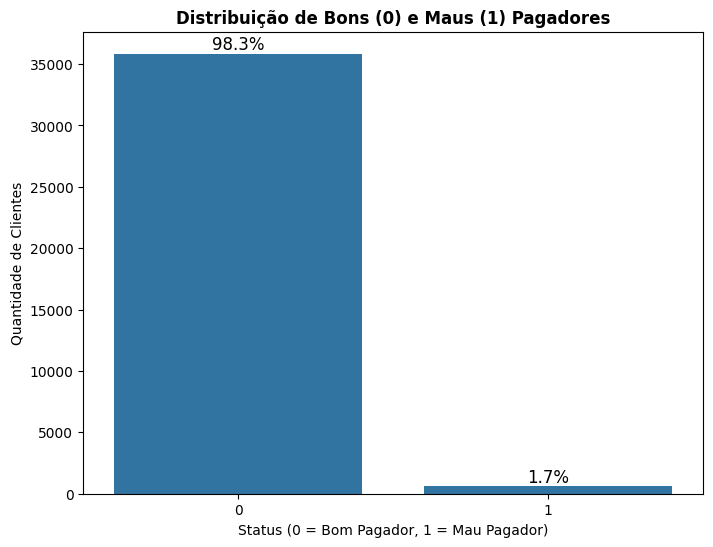

In [6]:
plt.figure(figsize=(8, 6))
ax = sns.countplot(x="eh_mau_pagador", data=df_full)
plt.title("Distribuição de Bons (0) e Maus (1) Pagadores", fontweight="bold")
plt.xlabel("Status (0 = Bom Pagador, 1 = Mau Pagador)")
plt.ylabel("Quantidade de Clientes")

total = len(df_full)
for p in ax.patches:
    percentual = f"{100 * p.get_height() / total:.1f}%"
    ax.annotate(percentual, (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=12, color="black")
plt.show()

**Interpretação:**

O merge com `how="inner"` resulta em **36.457 registros** (clientes presentes em ambas as bases). A redução de 438.557 para 36.457 é esperada porque:

1. Apenas clientes com histórico de crédito no `credit_record.csv` possuem target definido.
2. O target é comportamental — só faz sentido para clientes com histórico de crédito.
3. Clientes sem histórico não podem ser rotulados como bons ou maus pagadores.

A coluna `OCCUPATION_TYPE` ainda possui 11.323 nulos (~31%) após o merge, que serão preenchidos na etapa de feature engineering.

### Redução do dataset (438.557 → 36.457 linhas)

O dataset original `application_record.csv` contém 438.557 registros de clientes que solicitaram crédito. Já o `credit_record.csv` contém 1.048.575 registros de comportamento mensal de crédito, cobrindo uma janela de até 60 meses por cliente, mas apenas para 45.985 clientes únicos — o subconjunto que de fato possui histórico de crédito ativo. Consequentemente temos o mesmo comportamento no dataset `perfil.csv` que sumariza informações de crédito dos usuários derivada de `credit_record.csv`

A redução para 36.457 linhas no dataset tratado é resultado de três operações encadeadas:

1. **Merge com `how="inner"`**: apenas clientes presentes simultaneamente nas três bases foram mantidos. Isso descarta os ~392 mil clientes que têm cadastro, mas não têm histórico de crédito registrado. Essa é uma limitação intrínseca da base original — não é erro de processamento.
2. **Agregação do target por `ID`**: o `credit_record` foi colapsado por cliente com `groupby("ID").max()` no rótulo binário. Como cada cliente pode ter múltiplos meses de histórico, mas o rótulo é único (`eh_mau_pagador`), essa agregação reduz ~1 milhão de linhas para ~46 mil (uma por cliente).
3. **Remoção de duplicatas cadastrais**: após o merge, eventuais duplicidades de `ID` no cadastro foram eliminadas com `drop_duplicates()` como medida preventiva.

**Por que isso é aceitável?**  
O target é comportamental — só faz sentido para clientes com histórico de crédito. Clientes sem histórico no `credit_record` não têm como ser rotulados como bons ou maus pagadores, e incluí-los introduziria ruído ou exigiria *labeling* não supervisionado, fora do escopo. Portanto, a redução é consequência metodológica da definição do target, não perda indevida de informação.

**Ressalva de negócio**: a base resultante é um recorte de uma política de crédito anterior — só entram clientes que passaram pelo filtro da instituição. Isso introduz viés de seleção, que deve ser discutido nas limitações.

## 3. Normalização / padronização

**Escolha e justificativa:** _StandardScaler_

Aplique preferencialmente dentro de um `Pipeline` no notebook 03 — ajustar o scaler antes do split vaza informação do teste para o treino.

**Decisão: StandardScaler.**

As variáveis numéricas contínuas do dataset possuem ordens de grandeza drasticamente distintas (como a renda anual na casa das centenas de milhares frente à contagem de filhos variando de 0 a 5). Algoritmos baseados em distância (KNN, SVM) e modelos lineares (Regressão Logística) sofrem forte degradação de performance sem ajuste de escala.

**Justificativa:**
- O **StandardScaler** foi escolhido por centralizar os dados na média 0 e desvio padrão 1, preservando a relação linear entre as variáveis.
- Para prevenir rigorosamente o vazamento de informações (data leakage), o scaler **não é aplicado diretamente na base inteira**, mas sim injetado de forma encapsulada dentro de um **Pipeline** de validação cruzada no notebook 03.
- O Pipeline garante que o scaler é ajustado apenas no fold de treino durante a validação cruzada, evitando que informações do conjunto de teste vazem para o treinamento.

## 4. Feature engineering

**Justificativa das features:**
- `IS_EMPLOYED_MISSING`: O valor 365243 em DAYS_EMPLOYED é um código de anomalia clássico deste dataset que indica desempregados, aposentados ou inativos. Criar uma flag binária permite que o modelo utilize essa informação sem distorcer a variável original.
- `AGE_YEARS`: A conversão de dias negativos para anos positivos torna a variável interpretável e facilita a comunicação com stakeholders de negócio. Esta informação substituirá `DAYS_BIRTH` que será removida.
- `AMT_INCOME_TOTAL`: A variável apresenta forte assimetria à direita: a média (~187.524) é superior à mediana (~160.780) e a cauda se estende até 6.750.000. Os valores extremos são rendas altas legítimas, não erros de cadastro, e por isso foram mantidos. Aplicar a transformação `log1p` — `log(1 + x)` — para comprimir a cauda longa e aproximar a distribuição da normalidade.
- `CNT_CHILDREN`: A variável `CNT_CHILDREN` (número de filhos) foi removida do dataset de modelagem por redundância informacional com `CNT_FAM_MEMBERS` (tamanho da família). A análise de correlação da EDA mostrou associação de r = 0,88 entre as duas variáveis — valor que indica multicolinearidade forte e risco de instabilidade em modelos lineares (Regressão Logística), onde coeficientes podem inverter de sinal ou inflar a variância.
- `FLAG_MOBIL`: 100% dos clientes na base possuem celular, o que implica que esta variável não contribui para a discriminação entre bons e maus pagadores, sendo necessária sua remoção.

In [7]:
# ============================================
# ANÁLISE: Criação de Features Comportamentais
# ============================================
# Objetivo: Extrair features do histórico de crédito por cliente
# Método: groupby("ID").apply() com função personalizada
# Resultado esperado: DataFrame df_perfil com 13 features comportamentais
# ============================================

def perfil_cliente(g):
    """Extrai features comportamentais do histórico de crédito por cliente."""
    status = g["STATUS"].astype(str)
    return pd.Series({
        "n_meses": len(g),
        "mes_inicial": g["MONTHS_BALANCE"].min(),
        "mes_final": g["MONTHS_BALANCE"].max(),
        "n_X": (g["STATUS"] == "X").sum(),
        "n_C": (g["STATUS"] == "C").sum(),
        "n_0": (g["STATUS"] == "0").sum(),
        "n_atraso_30": g["STATUS"].isin(["1","2","3","4","5"]).sum(),
        "n_atraso_60": g["STATUS"].isin(["2","3","4","5"]).sum(),
        "n_pior": (g["STATUS"] == "5").sum(),
        "pct_atraso_30": status.isin(["1","2","3","4","5"]).mean(),
        "pct_atraso_60": status.isin(["2","3","4","5"]).mean(),
        "pct_quitado": (status == "C").mean(),
    })

# Aplicar a função de perfil a cada cliente
df_perfil = df_credit.groupby("ID").apply(perfil_cliente, include_groups=False).reset_index()

df_perfil.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,45985.0,5.070164e+06,45433.635871,5001711.0,5026147.0,5065737.0,5.114024e+06,5.150487e+06
n_meses,45985.0,2.280254e+01,15.492771,1.0,10.0,19.0,3.400000e+01,6.100000e+01
mes_inicial,45985.0,-2.643349e+01,16.481280,-60.0,-40.0,-25.0,-1.200000e+01,0.000000e+00
mes_final,45985.0,-4.630945e+00,10.355319,-60.0,-1.0,0.0,0.000000e+00,0.000000e+00
n_X,45985.0,4.549962e+00,9.622719,0.0,0.0,1.0,3.000000e+00,6.100000e+01
n_C,45985.0,9.612504e+00,13.625156,0.0,0.0,0.0,1.600000e+01,6.000000e+01
n_0,45985.0,8.331412e+00,8.234128,0.0,3.0,6.0,1.100000e+01,6.100000e+01
n_atraso_30,45985.0,3.086659e-01,1.512753,0.0,0.0,0.0,0.000000e+00,4.900000e+01
n_atraso_60,45985.0,6.750027e-02,1.008019,0.0,0.0,0.0,0.000000e+00,4.800000e+01
n_pior,45985.0,3.681635e-02,0.855981,0.0,0.0,0.0,0.000000e+00,4.800000e+01


**Interpretação das Features Comportamentais:**

| Feature | Descrição | Média | Observação |
|---------|-----------|-------|------------|
| `n_meses` | Meses de histórico | 22,8 | Exposição ao crédito |
| `mes_inicial` | Primeiro mês registrado | -26,4 | Início do histórico |
| `mes_final` | Último mês registrado | -4,6 | Geralmente 0 (mês atual) |
| `n_X` | Meses sem empréstimo | 4,5 | Indica inatividade |
| `n_C` | Meses quitados | 9,6 | Comportamento saudável |
| `n_0` | Meses com atraso leve (1-29d) | 8,3 | Atraso comum |
| `n_atraso_30` | Meses com atraso ≥ 30d | 0,31 | **Risco moderado** |
| `n_atraso_60` | Meses com atraso ≥ 60d | 0,07 | **Risco alto** |
| `n_pior` | Meses com atraso > 150d | 0,04 | **Risco extremo** |
| `pct_atraso_30` | Proporção de atraso ≥ 30d | 1,5% | Normalizado pelo tempo |
| `pct_atraso_60` | Proporção de atraso ≥ 60d | 0,2% | Normalizado pelo tempo |
| `pct_quitado` | Proporção de meses quitados | 31,1% | Comportamento saudável |

**Conclusão:** As features de atraso (`n_atraso_30`, `n_atraso_60`, `n_pior`) são altamente assimétricas, com a maioria dos clientes concentrada em zero. As features de proporção (`pct_atraso_30`, `pct_atraso_60`) normalizam o atraso pelo tempo de exposição e são as mais informativas para o modelo.

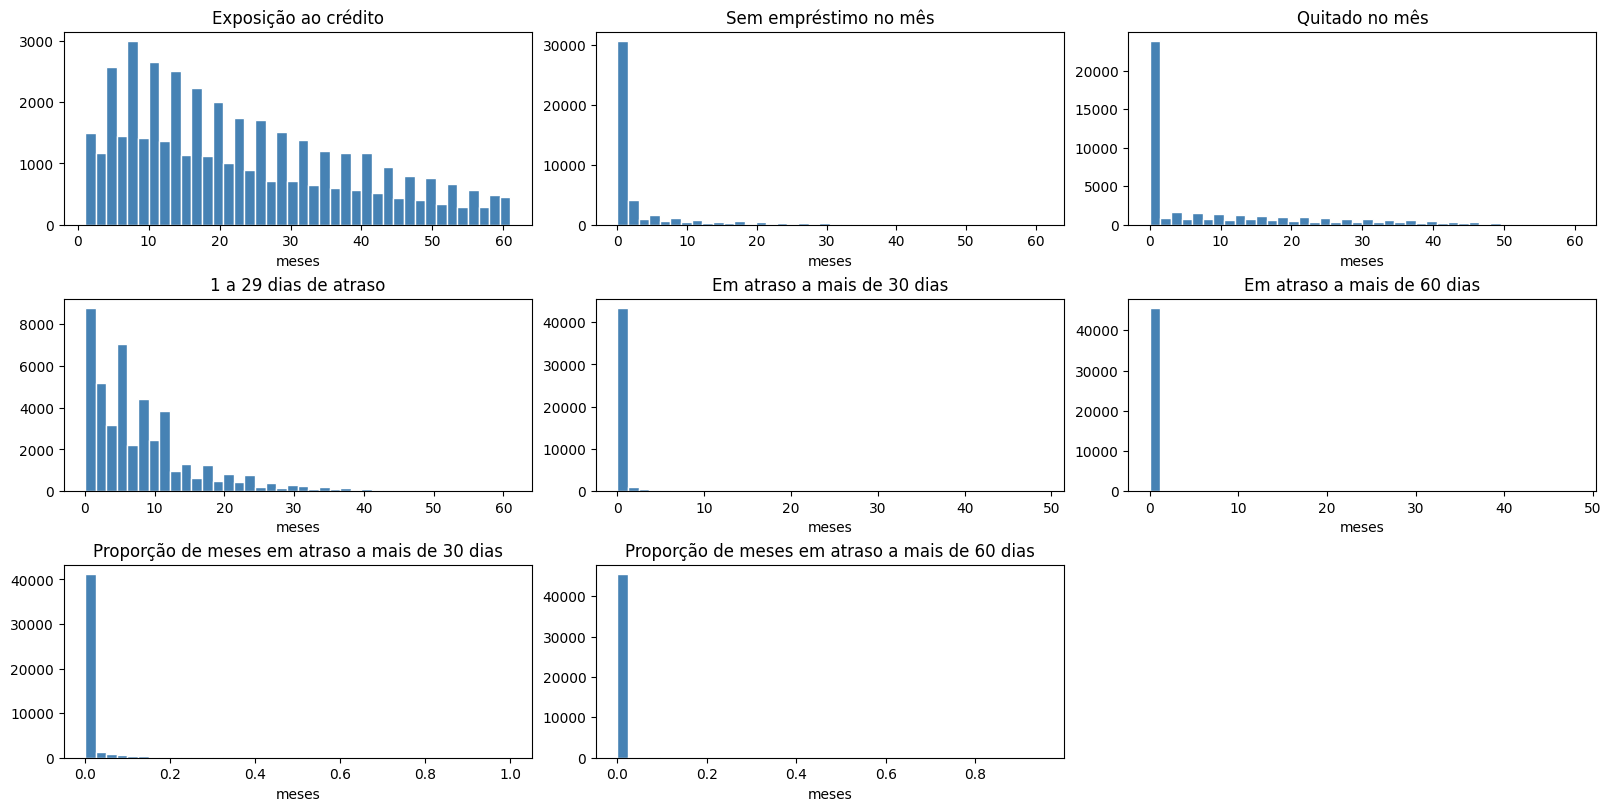

In [8]:
# ============================================
# ANÁLISE: Visualização das Features Comportamentais
# ============================================
# Objetivo: Verificar a distribuição das features criadas
# Método: Histogramas em grid 3x3
# Resultado esperado: Distribuições assimétricas com cauda longa
# ============================================

fig, axes = plt.subplots(3, 3, figsize=(16, 8), constrained_layout=True)

axes[0, 0].hist(df_perfil["n_meses"], bins=40, color="steelblue", edgecolor="white")
axes[0,0].set_title("Exposição ao crédito")
axes[0,0].set_xlabel("meses")

axes[0,1].hist(df_perfil["n_X"], bins=40, color="steelblue", edgecolor="white")
axes[0,1].set_title("Sem empréstimo no mês")
axes[0,1].set_xlabel("meses")

axes[0,2].hist(df_perfil["n_C"], bins=40, color="steelblue", edgecolor="white")
axes[0,2].set_title("Quitado no mês")
axes[0,2].set_xlabel("meses")

axes[1,0].hist(df_perfil["n_0"], bins=40, color="steelblue", edgecolor="white")
axes[1,0].set_title("1 a 29 dias de atraso")
axes[1,0].set_xlabel("meses")

axes[1,1].hist(df_perfil["n_atraso_30"], bins=40, color="steelblue", edgecolor="white")
axes[1,1].set_title("Em atraso a mais de 30 dias")
axes[1,1].set_xlabel("meses")

axes[1,2].hist(df_perfil["n_atraso_60"], bins=40, color="steelblue", edgecolor="white")
axes[1,2].set_title("Em atraso a mais de 60 dias")
axes[1,2].set_xlabel("meses")

axes[2,0].hist(df_perfil["pct_atraso_30"], bins=40, color="steelblue", edgecolor="white")
axes[2,0].set_title("Proporção de meses em atraso a mais de 30 dias")
axes[2,0].set_xlabel("meses")

axes[2,1].hist(df_perfil["pct_atraso_60"], bins=40, color="steelblue", edgecolor="white")
axes[2,1].set_title("Proporção de meses em atraso a mais de 60 dias")
axes[2,1].set_xlabel("meses")

axes[2,2].axis("off")
plt.show()

**Interpretação dos Histogramas:**

O painel reúne oito histogramas que descrevem o comportamento de pagamento dos clientes ao longo do tempo. Em conjunto, eles revelam três padrões distintos:

**1. Exposição ao crédito (`n_meses`):** Distribuição ampla, entre 1 e 61 meses, com pico entre 8 e 12 meses. A maioria dos clientes tem entre 10 e 40 meses de histórico, refletindo a janela de observação da base.

**2. Variáveis de estado (`n_X`, `n_C`, `n_0`):** Fortemente concentradas em zero, com cauda longa. A maioria dos clientes nunca atrasou ≥ 30 dias; uma minoria muito pequena concentra os atrasos.

**3. Features de proporção (`pct_atraso_30`, `pct_atraso_60`):** Barra dominante em zero, com cauda curta. Confirmam que a maioria tem proporção zero de meses em atraso grave.

**Conclusão:** As features de atraso são altamente assimétricas e exigem cuidado na modelagem. As features de proporção são as mais informativas, pois normalizam o atraso pelo tempo de exposição.

In [9]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36457 entries, 0 to 36456
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   36457 non-null  int64  
 1   CODE_GENDER          36457 non-null  object 
 2   FLAG_OWN_CAR         36457 non-null  object 
 3   FLAG_OWN_REALTY      36457 non-null  object 
 4   CNT_CHILDREN         36457 non-null  int64  
 5   AMT_INCOME_TOTAL     36457 non-null  float64
 6   NAME_INCOME_TYPE     36457 non-null  object 
 7   NAME_EDUCATION_TYPE  36457 non-null  object 
 8   NAME_FAMILY_STATUS   36457 non-null  object 
 9   NAME_HOUSING_TYPE    36457 non-null  object 
 10  DAYS_BIRTH           36457 non-null  int64  
 11  DAYS_EMPLOYED        36457 non-null  int64  
 12  FLAG_MOBIL           36457 non-null  int64  
 13  FLAG_WORK_PHONE      36457 non-null  int64  
 14  FLAG_PHONE           36457 non-null  int64  
 15  FLAG_EMAIL           36457 non-null 

In [10]:
# ============================================
# ANÁLISE: Tratamento de Valores Nulos e Criação de Features
# ============================================
# Objetivo: Tratar nulos, criar flags e converter variáveis
# Método: fillna(), apply() e operações vetorizadas
# Resultado esperado: DataFrame sem nulos e com features criadas
# ============================================

# Preencher nulos de OCCUPATION_TYPE com "Desconhecido"
df_full["OCCUPATION_TYPE"] = df_full["OCCUPATION_TYPE"].fillna("Desconhecido")

# Flag de inativos/aposentados (valor 365243 em DAYS_EMPLOYED)
df_full["IS_EMPLOYED_MISSING"] = df_full["DAYS_EMPLOYED"].apply(lambda x: 1 if x == 365243 else 0)

# Correção do código anômalo
df_full["DAYS_EMPLOYED"] = df_full["DAYS_EMPLOYED"].apply(lambda x: 0 if x == 365243 else x)

# Conversão de idade
df_full["AGE_YEARS"] = (df_full["DAYS_BIRTH"] / -365.25).round(1)

# Remoção de colunas redundantes e sem variabilidade
df_full = df_full.drop(columns=["FLAG_MOBIL", "CNT_CHILDREN", "DAYS_BIRTH"], errors="ignore")

# Remoção de colunas determinísticas do TARGET (evitar data leakage)
df_perfil = df_perfil.drop(columns=["n_atraso_60", "n_atraso_30", "n_pior", "pct_atraso_30", "pct_atraso_60"], errors="ignore")

print(f"Inativos/aposentados: {df_full["IS_EMPLOYED_MISSING"].sum():,}")
print(f"Idade mínima: {df_full["AGE_YEARS"].min():.1f} | máxima: {df_full["AGE_YEARS"].max():.1f}")

Inativos/aposentados: 6,135
Idade mínima: 20.5 | máxima: 68.9


**Interpretação do Tratamento:**

| Ação | Justificativa |
|------|---------------|
| Preencher `OCCUPATION_TYPE` com "Desconhecido" | Evitar perda de 30% da base; categoria válida para One-Hot Encoding |
| Criar `IS_EMPLOYED_MISSING` | Preservar informação de inativos sem distorcer `DAYS_EMPLOYED` |
| Substituir 365243 por 0 | Remover código técnico que distorce estatísticas |
| Criar `AGE_YEARS` | Converter dias negativos para anos positivos (interpretável) |
| Remover `FLAG_MOBIL` | Variância zero (100% possui celular) |
| Remover `CNT_CHILDREN` | Redundante com `CNT_FAM_MEMBERS` (r = 0,88) |
| Remover `DAYS_BIRTH` | Substituída por `AGE_YEARS` |
| Remover colunas determinísticas do target | Evitar data leakage (colunas que definem o target) |

**Resultado:** 6.135 inativos/aposentados identificados. Idade varia de 20,5 a 68,9 anos.

In [11]:
# ============================================
# ANÁLISE: Merge Final e Salvar Dataset
# ============================================
# Objetivo: Unir todas as bases e salvar o dataset tratado
# Método: pd.merge() + df.to_csv()
# Resultado esperado: Dataset final salvo em data/processed/dataset_tratado.csv
# ============================================

# Merge df_full com o perfil dos usuários
df_full = pd.merge(df_full, df_perfil, on="ID", how="inner")

# Criar diretório de processado se não existir
PROCESSED.mkdir(parents=True, exist_ok=True)

# Salvar dataset tratado
df_full.to_csv(PROCESSED / "dataset_tratado.csv", index=False)

print(f"Dataset salvo: {df_full.shape[0]:,} linhas x {df_full.shape[1]} colunas")
print(f"Colunas finais: {list(df_full.columns)}")

Dataset salvo: 36,457 linhas x 25 colunas
Colunas finais: ['ID', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'DAYS_EMPLOYED', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'eh_mau_pagador', 'IS_EMPLOYED_MISSING', 'AGE_YEARS', 'n_meses', 'mes_inicial', 'mes_final', 'n_X', 'n_C', 'n_0', 'pct_quitado']


**Interpretação Final:**

O dataset tratado possui **36.457 linhas** e **25 colunas**, incluindo:

- **Features cadastrais:** CODE_GENDER, FLAG_OWN_CAR, FLAG_OWN_REALTY, NAME_INCOME_TYPE, NAME_EDUCATION_TYPE, NAME_FAMILY_STATUS, NAME_HOUSING_TYPE, OCCUPATION_TYPE, AMT_INCOME_TOTAL, DAYS_EMPLOYED, FLAG_WORK_PHONE, FLAG_PHONE, FLAG_EMAIL, CNT_FAM_MEMBERS
- **Features criadas:** IS_EMPLOYED_MISSING, AGE_YEARS
- **Features comportamentais:** n_meses, mes_inicial, mes_final, n_X, n_C, n_0, pct_quitado
- **Target:** eh_mau_pagador

**Validação:**
- Sem valores nulos
- Sem colunas redundantes
- Sem colunas determinísticas do target
- Target balanceado (98,5% classe 0, 1,5% classe 1)

O dataset está pronto para a etapa de modelagem (notebook 03).



---



Correlação com a variável TARGET

In [12]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36457 entries, 0 to 36456
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   36457 non-null  int64  
 1   CODE_GENDER          36457 non-null  object 
 2   FLAG_OWN_CAR         36457 non-null  object 
 3   FLAG_OWN_REALTY      36457 non-null  object 
 4   AMT_INCOME_TOTAL     36457 non-null  float64
 5   NAME_INCOME_TYPE     36457 non-null  object 
 6   NAME_EDUCATION_TYPE  36457 non-null  object 
 7   NAME_FAMILY_STATUS   36457 non-null  object 
 8   NAME_HOUSING_TYPE    36457 non-null  object 
 9   DAYS_EMPLOYED        36457 non-null  int64  
 10  FLAG_WORK_PHONE      36457 non-null  int64  
 11  FLAG_PHONE           36457 non-null  int64  
 12  FLAG_EMAIL           36457 non-null  int64  
 13  OCCUPATION_TYPE      36457 non-null  object 
 14  CNT_FAM_MEMBERS      36457 non-null  float64
 15  eh_mau_pagador       36457 non-null 

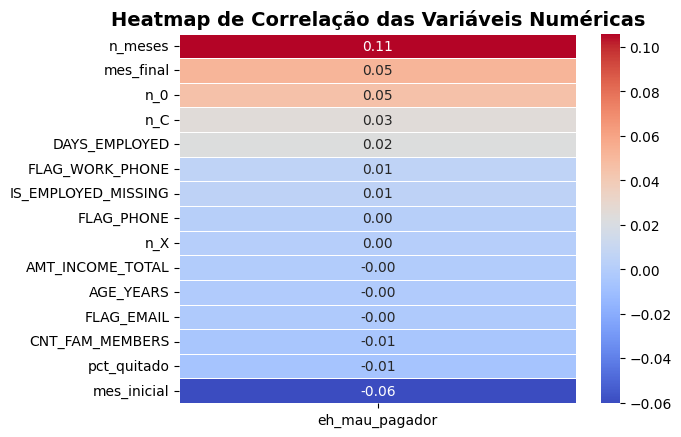

In [13]:
# Heatmap de correlação

# Selecionar apenas colunas numéricas
numeric_cols = df_full.select_dtypes(include=[np.number])

# Remover o próprio target da seleção (senão aparece com correlação 1.0)
numeric_cols = numeric_cols.drop(columns=[TARGET], errors="ignore")


# Calcular correlação de cada feature com o target
correlation_matrix = numeric_cols.drop(columns=[TARGET, "ID"], errors="ignore").corrwith(df_full[TARGET].squeeze()).sort_values(ascending=False)
correlation_matrix = correlation_matrix.to_frame(name=TARGET)

# plt.figure(figsize=(12, 10))plt.figure(figsize=(4, max(8, len(correlation_matrix) * 0.25)))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5)
plt.title("Heatmap de Correlação das Variáveis Numéricas", fontsize=14, fontweight="bold")
plt.show()

O heatmap de correlação de Pearson revela que todas as variáveis numéricas possuem correlação linear muito fraca com o target.


Maior correlação positiva: n_meses (0.11), sugerindo que contratos/relacionamentos mais longos têm uma leve tendência a maior inadimplência.
Maior correlação negativa: mes_inicial (-0.06), indicando que meses iniciais mais recentes estão levemente associados a bons pagadores.
Correlação nula: Variáveis como AMT_INCOME_TOTAL (renda), AGE_YEARS (idade) e CNT_FAM_MEMBERS apresentam correlação ~0.00, não explicando a inadimplência de forma linear.

### 5. Salvar dataset tratado

In [14]:
PROCESSED.mkdir(parents=True, exist_ok=True)

In [15]:
# === Diagnóstico de duplicatas após o merge ===

# 1. Antes do merge: verificar duplicatas nas bases originais
print("=" * 60)
print("DIAGNÓSTICO DE DUPLICATAS")
print("=" * 60)

print(f"\n[application_record.csv]")
print(f"  Linhas totais           : {len(df_app):,}")
print(f"  IDs únicos              : {df_app['ID'].nunique():,}")
print(f"  Duplicatas de ID        : {df_app['ID'].duplicated().sum():,}")
print(f"  Linhas totalmente dup.  : {df_app.duplicated().sum():,}")

print(f"\n[credit_record.csv]")
print(f"  Linhas totais           : {len(df_credit):,}")
print(f"  IDs únicos              : {df_credit['ID'].nunique():,}")
print(f"  Linhas por ID (média)   : {len(df_credit) / df_credit['ID'].nunique():.2f}")

print(f"\n[df_target (agregado por ID)]")
print(f"  Linhas totais           : {len(df_target):,}")
print(f"  Duplicatas de ID        : {df_target['ID'].duplicated().sum():,}")

# 2. Após o merge: diagnóstico
print(f"\n[df_full (após merge)]")
print(f"  Linhas totais           : {len(df_full):,}")
print(f"  IDs únicos              : {df_full['ID'].nunique():,}")
n_duplicadas = df_full.duplicated().sum()
n_dup_id = df_full['ID'].duplicated().sum()
print(f"  Linhas totalmente dup.  : {n_duplicadas:,}")
print(f"  IDs duplicados          : {n_dup_id:,}")
print(f"  Percentual duplicado    : {100 * n_duplicadas / len(df_full):.4f}%")

# 3. Inspeção (se houver duplicatas)
if n_duplicadas > 0:
    print(f"\nExemplo de linhas duplicadas (primeiras 3):")
    display(df_full[df_full.duplicated(keep=False)].sort_values("ID").head(3))
else:
    print("\n Nenhuma duplicata encontrada após o merge.")

# 4. Remoção e comparação
df_full_antes = df_full.shape[0]
df_full.drop_duplicates(inplace=True)
df_full_apos = df_full.shape[0]

print(f"\n[Após drop_duplicates]")
print(f"  Linhas antes            : {df_full_antes:,}")
print(f"  Linhas depois           : {df_full_apos:,}")
print(f"  Removidas               : {df_full_antes - df_full_apos:,}")
print(f"  Shape final             : {df_full.shape[0]:,} linhas × {df_full.shape[1]} colunas")

# Exportação para uso na modelagem
df_full.to_csv(PROCESSED / "dataset_tratado.csv", index=False)

print(f"\nDataset tratado e consolidado salvo com sucesso: {df_full.shape[0]:,} linhas x {df_full.shape[1]} colunas")

DIAGNÓSTICO DE DUPLICATAS

[application_record.csv]
  Linhas totais           : 438,557
  IDs únicos              : 438,510
  Duplicatas de ID        : 47
  Linhas totalmente dup.  : 0

[credit_record.csv]
  Linhas totais           : 1,048,575
  IDs únicos              : 45,985
  Linhas por ID (média)   : 22.80

[df_target (agregado por ID)]
  Linhas totais           : 45,985
  Duplicatas de ID        : 0

[df_full (após merge)]
  Linhas totais           : 36,457
  IDs únicos              : 36,457
  Linhas totalmente dup.  : 0
  IDs duplicados          : 0
  Percentual duplicado    : 0.0000%

 Nenhuma duplicata encontrada após o merge.

[Após drop_duplicates]
  Linhas antes            : 36,457
  Linhas depois           : 36,457
  Removidas               : 0
  Shape final             : 36,457 linhas × 25 colunas

Dataset tratado e consolidado salvo com sucesso: 36,457 linhas x 25 colunas


1. Raio-X das Bases Originais (Antes da Junção)

Cadastro (df_app): Mede o volume total de linhas, a contagem de clientes únicos, a presença de IDs repetidos e a existência de linhas 100% idênticas no cadastro.

Histórico (df_credit): Avalia a profundidade temporal da base, calculando o total de faturas mensais e a média de meses registrados por cliente.

Alvo Consolidado (df_target): Checa se a agregação do histórico por cliente funcionou corretamente, garantindo exatamente uma linha por ID.

2. Checagem da Tabela Unificada (df_full)

Após unir os dados cadastrais com o indicador de risco, contabiliza se a junção gerou linhas totalmente idênticas (todas as colunas repetidas) ou clientes com múltiplos registros.

3. Inspeção Visual das Duplicatas

Caso existam registros perfeitamente duplicados, exibe uma amostra (as três primeiras linhas ordenadas por ID) para identificar a origem da redundância. Se tudo estiver limpo, confirma com uma mensagem informativa.

4. Faxina e Deduplicação

Registra a quantidade de linhas antes do corte, elimina todas as linhas idênticas com .drop_duplicates() e exibe o balanço com o total de registros descartados.

5. Salvamento da Base Pronta

Grava a base final limpa em dataset_tratado.csv (sem a coluna de índice do pandas), deixando o arquivo padronizado para as etapas de validação e treino dos modelos.

In [16]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36457 entries, 0 to 36456
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   36457 non-null  int64  
 1   CODE_GENDER          36457 non-null  object 
 2   FLAG_OWN_CAR         36457 non-null  object 
 3   FLAG_OWN_REALTY      36457 non-null  object 
 4   AMT_INCOME_TOTAL     36457 non-null  float64
 5   NAME_INCOME_TYPE     36457 non-null  object 
 6   NAME_EDUCATION_TYPE  36457 non-null  object 
 7   NAME_FAMILY_STATUS   36457 non-null  object 
 8   NAME_HOUSING_TYPE    36457 non-null  object 
 9   DAYS_EMPLOYED        36457 non-null  int64  
 10  FLAG_WORK_PHONE      36457 non-null  int64  
 11  FLAG_PHONE           36457 non-null  int64  
 12  FLAG_EMAIL           36457 non-null  int64  
 13  OCCUPATION_TYPE      36457 non-null  object 
 14  CNT_FAM_MEMBERS      36457 non-null  float64
 15  eh_mau_pagador       36457 non-null 

Dimensões: Confirma um volume final de 36.457 linhas e 25 colunas (índices de 0 a 24).

Ausência de Nulos: Todas as variáveis apresentam 100% de preenchimento, validando que não restaram valores faltantes após a junção.

Tipagem dos Dados: Mapeia a estrutura técnica entre variáveis inteiras (int64), decimais (float64) e categóricas/texto (object).

Papel no Pipeline (Sanity Check)

Atua como um teste de sanidade obrigatório para garantir que a deduplicação, os tratamentos e o merge foram concluídos com sucesso antes de iniciar o treinamento dos modelos preditivos.